# Linear Regression with One Variable: Gradient Descent from Scratch

**Course:** Machine Learning Specialization (Andrew Ng) - Course 1, Week 1
**Author:** Muhammad Aqib

In this notebook I implement linear regression with one feature **from scratch** (no ML library for training), then verify the result against scikit-learn.

## Workflow

1. Implement the cost function, the gradient, and gradient descent
2. Sanity-check the functions on a tiny dataset with known answers
3. **Experiment 1:** train on synthetic data (`y = 3x + 7 + noise`) and verify with scikit-learn
4. **Experiment 2:** train on a real Experience-Salary dataset
5. Study the effect of the learning rate (alpha) on raw, unscaled data
6. Visualize the best-fit line and the cost curve
7. Key learnings

## 0. Setup

In [3]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

## 1. The Math

**Model:** $f_{w,b}(x) = wx + b$

**Cost function (mean squared error):**

$$J(w,b) = \frac{1}{2m}\sum_{i=0}^{m-1}\left(f_{w,b}(x^{(i)}) - y^{(i)}\right)^2$$

**Gradients:**

$$\frac{\partial J}{\partial w} = \frac{1}{m}\sum_{i=0}^{m-1}\left(f_{w,b}(x^{(i)}) - y^{(i)}\right)x^{(i)} \qquad \frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=0}^{m-1}\left(f_{w,b}(x^{(i)}) - y^{(i)}\right)$$

**Gradient descent update (both parameters updated simultaneously):**

$$w = w - \alpha\frac{\partial J}{\partial w} \qquad b = b - \alpha\frac{\partial J}{\partial b}$$

> **Notation note:** In the lecture slides the sum runs from $i=1$ to $m$, while in Python (0-indexed) it runs from $i=0$ to $m-1$. It is the same formula. Also, $x^{(i)}$ means "the $i$-th training example", not "$x$ to the power $i$".

## 2. Implementation

In [4]:
def compute_cost(x, y, w, b):
    """Mean squared error cost J(w, b) for linear regression."""
    m = x.shape[0]
    total_cost = 0
    for i in range(m):
        f_wb = w * x[i] + b
        total_cost += (f_wb - y[i]) ** 2
    return total_cost / (2 * m)


def compute_gradient(x, y, w, b):
    """Return dJ/dw and dJ/db at the current (w, b)."""
    m = x.shape[0]
    dj_dw, dj_db = 0, 0
    for i in range(m):
        f_wb = w * x[i] + b
        dj_dw += (f_wb - y[i]) * x[i]   # extra factor x[i] comes from d(f)/dw = x
        dj_db += (f_wb - y[i])          # d(f)/db = 1
    return dj_dw / m, dj_db / m


def gradient_descent(x, y, w_init, b_init, alpha, num_iters,
                     gradient_function=compute_gradient,
                     cost_function=compute_cost,
                     tol=None, log_every=1000, verbose=True):
    """
    Batch gradient descent.

    Stops early if the cost improvement per iteration falls below `tol`
    (when tol is given), or if the cost diverges (becomes inf/nan).
    Returns the learned w, b and the cost history.
    """
    w, b = w_init, b_init
    J_history = []

    
    for i in range(num_iters):
         # compute both gradients at the CURRENT (w, b), then update together
        dj_dw, dj_db = gradient_function(x, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        cost = cost_function(x, y, w, b)
        J_history.append(cost)

        if not np.isfinite(cost):
            print(f"Diverged at iteration {i}: cost became {cost}. Try a smaller alpha.")
            break

        if verbose and i % log_every == 0:
            print(f"iter {i:6d} | cost: {cost:.4f} | w: {w:.4f} | b: {b:.4f}")

        if tol is not None and i > 0 and abs(J_history[-2] - J_history[-1]) < tol:
            print(f"Converged at iteration {i} (cost change < {tol}).")
            break

    return w, b, J_history


def train_and_predict(x, y, w_init, b_init, alpha, num_iters, **kwargs):
    
    """Train the model, then return parameters, predictions and the final cost."""
    w, b, J_history = gradient_descent(x, y, w_init, b_init, alpha, num_iters, **kwargs)
    y_pred = w * x + b
    final_cost = compute_cost(x, y, w, b)
    return w, b, y_pred, final_cost, J_history

## 3. Sanity check on a tiny dataset

Two points, $(1, 300)$ and $(2, 500)$, lie exactly on the line $y = 200x + 100$, so every answer below can be verified by hand.

In [5]:
x_tiny = np.array([1.0, 2.0])
y_tiny = np.array([300.0, 500.0])

assert compute_cost(x_tiny, y_tiny, 200, 100) == 0.0         # perfect fit -> zero cost
assert compute_cost(x_tiny, y_tiny, 0, 0) == 85000.0         # (300^2 + 500^2) / (2*2)
assert compute_gradient(x_tiny, y_tiny, 0, 0) == (-650.0, -400.0)
print("All sanity checks passed.")

All sanity checks passed.


## 4. Plotting helpers

In [6]:
def plot_fit(x, y, w, b, xlabel, ylabel, title, compare=True):
    """Scatter plot of the data with the learned line (and the sklearn/polyfit line)."""
    x_line = np.linspace(x.min(), x.max(), 100)
    plt.figure(figsize=(8, 5))
    plt.scatter(x, y, color="steelblue", alpha=0.7, label="Data points")
    plt.plot(x_line, w * x_line + b, color="red", linewidth=2,
             label=f"My gradient descent: y = {w:.2f}x + {b:.2f}")
    if compare:
        w_ref, b_ref = np.polyfit(x, y, 1)
        plt.plot(x_line, w_ref * x_line + b_ref, "g--", linewidth=2,
                 label=f"np.polyfit: y = {w_ref:.2f}x + {b_ref:.2f}")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def plot_cost(J_history, title="Cost vs. iteration"):
    plt.figure(figsize=(8, 4))
    plt.plot(J_history)
    plt.xlabel("Iteration")
    plt.ylabel("Cost J(w, b)")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()


def sklearn_reference(x, y):
    """Fit scikit-learn's LinearRegression and return (w, b, cost)."""
    model = LinearRegression().fit(x.reshape(-1, 1), y)   # sklearn expects a 2-D X
    w_sk, b_sk = model.coef_[0], model.intercept_
    return w_sk, b_sk, compute_cost(x, y, w_sk, b_sk)

## 5. Experiment 1: Synthetic data

I generate data from a known line, $y = 3x + 7$, and add Gaussian noise (std = 2). If the implementation is correct, gradient descent should recover values close to $w=3$ and $b=7$.
Because of the noise, the exact least-squares answer on these 100 points will be slightly different from 3 and 7.

In [7]:
np.random.seed(42)                       # same data on every run
m = 100
x_syn = np.random.uniform(0, 10, m)      # 100 inputs between 0 and 10
y_syn = 3 * x_syn + 7 + np.random.randn(m) * 2

In [8]:
w, b, y_pred, final_cost, J_syn = train_and_predict(
    x_syn, y_syn, w_init=0, b_init=0, alpha=0.01, num_iters=10000
)

print("\nMy own model")
print(f"  w = {w:.2f}")
print(f"  b = {b:.2f}")
print(f"  final cost = {final_cost:.4f}")

iter      0 | cost: 126.6346 | w: 1.2470 | b: 0.2110
iter   1000 | cost: 1.6386 | w: 2.9731 | b: 7.0070
iter   2000 | cost: 1.6133 | w: 2.9121 | b: 7.4039
iter   3000 | cost: 1.6132 | w: 2.9083 | b: 7.4286
iter   4000 | cost: 1.6132 | w: 2.9081 | b: 7.4301
iter   5000 | cost: 1.6132 | w: 2.9080 | b: 7.4302
iter   6000 | cost: 1.6132 | w: 2.9080 | b: 7.4302
iter   7000 | cost: 1.6132 | w: 2.9080 | b: 7.4302
iter   8000 | cost: 1.6132 | w: 2.9080 | b: 7.4302
iter   9000 | cost: 1.6132 | w: 2.9080 | b: 7.4302

My own model
  w = 2.91
  b = 7.43
  final cost = 1.6132


### Verification against scikit-learn

In [9]:
w_sk, b_sk, cost_sk = sklearn_reference(x_syn, y_syn)

print("Scikit-learn")
print(f"  w = {w_sk:.2f}")
print(f"  b = {b_sk:.2f}")
print(f"  final cost = {cost_sk:.4f}")

comparison = pd.DataFrame({
    "Actual": y_syn[:5],
    "My model": y_pred[:5],
    "Scikit-learn": LinearRegression().fit(x_syn.reshape(-1, 1), y_syn).predict(x_syn[:5].reshape(-1, 1)),
}).round(2)
comparison

Scikit-learn
  w = 2.91
  b = 7.43
  final cost = 1.6132


,Actual,My model,Scikit-learn
0,18.41,18.32,18.32
1,34.92,35.08,35.08
2,29.14,28.72,28.72
3,20.98,24.84,24.84
4,11.24,11.97,11.97


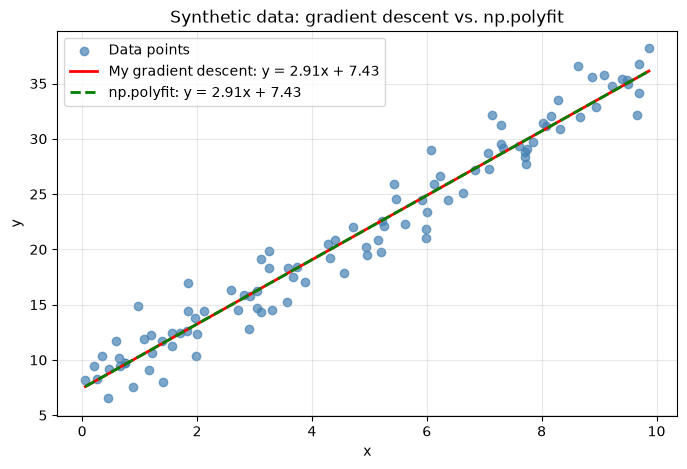

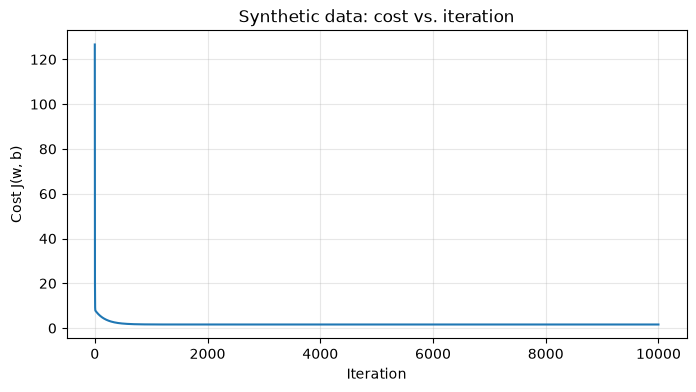

In [10]:
plot_fit(x_syn, y_syn, w, b, "x", "y", "Synthetic data: gradient descent vs. np.polyfit")
plot_cost(J_syn, "Synthetic data: cost vs. iteration")

**Result:** my gradient descent matches scikit-learn (same `w`, `b`, and cost), so the implementation is correct. The learned values are close to the true $w=3$, $b=7$ but not exactly equal, because the best line for these noisy points differs slightly from the hidden true line. The final cost is not zero for the same reason: noise cannot be fitted away by a straight line.

## 6. Experiment 2: Real data (Experience vs. Salary)

Now the same code on a real dataset. I use a random sample of 100 rows (a random sample, not the first 100 rows, because a file may be sorted and the first rows could be a biased slice).

Place the CSV at `data/Experience-Salary.csv`, with the columns `exp(in months)` and `salary(in thousands)`.

In [11]:

df = pd.read_csv("Experience-Salary.csv")
df = df.sample(n=100, random_state=42)           # random 100 rows, same every run

x_real = df["exp(in months)"].to_numpy()
y_real = df["salary(in thousands)"].to_numpy()

df.describe().round(2)

,exp(in months),salary(in thousands)
count,100.00,100.00
mean,26.66,26.79
std,8.88,8.27
min,8.90,6.54
25%,19.49,20.47
50%,26.88,27.14
75%,32.41,31.61
max,48.85,45.39


In [12]:
w_r, b_r, y_pred_r, cost_r, J_real = train_and_predict(
    x_real, y_real, w_init=0, b_init=0,
    alpha=0.001, num_iters=100000,
    tol=1e-10, log_every=10000,      # stop early once the cost stops improving
)

print("\nMy own model")
print(f"  w = {w_r:.2f}")
print(f"  b = {b_r:.2f}")
print(f"  final cost = {cost_r:.4f}")

w_sk_r, b_sk_r, cost_sk_r = sklearn_reference(x_real, y_real)
print("\nScikit-learn")
print(f"  w = {w_sk_r:.2f}")
print(f"  b = {b_sk_r:.2f}")
print(f"  final cost = {cost_sk_r:.4f}")

iter      0 | cost: 31.2064 | w: 0.7724 | b: 0.0268
iter  10000 | cost: 12.4987 | w: 0.8318 | b: 4.3555
iter  20000 | cost: 12.2193 | w: 0.7775 | b: 5.9628
iter  30000 | cost: 12.1807 | w: 0.7573 | b: 6.5607
iter  40000 | cost: 12.1754 | w: 0.7498 | b: 6.7830
iter  50000 | cost: 12.1746 | w: 0.7470 | b: 6.8657
iter  60000 | cost: 12.1745 | w: 0.7459 | b: 6.8965
iter  70000 | cost: 12.1745 | w: 0.7455 | b: 6.9079
Converged at iteration 77598 (cost change < 1e-10).

My own model
  w = 0.75
  b = 6.91
  final cost = 12.1745

Scikit-learn
  w = 0.75
  b = 6.91
  final cost = 12.1745


In [13]:
pd.DataFrame({"Actual": y_real[:5], "Predicted": y_pred_r[:5]}).round(2)

,Actual,Predicted
0,25.32,34.40
1,22.37,20.64
2,43.36,40.46
3,30.25,32.09
4,22.02,18.77


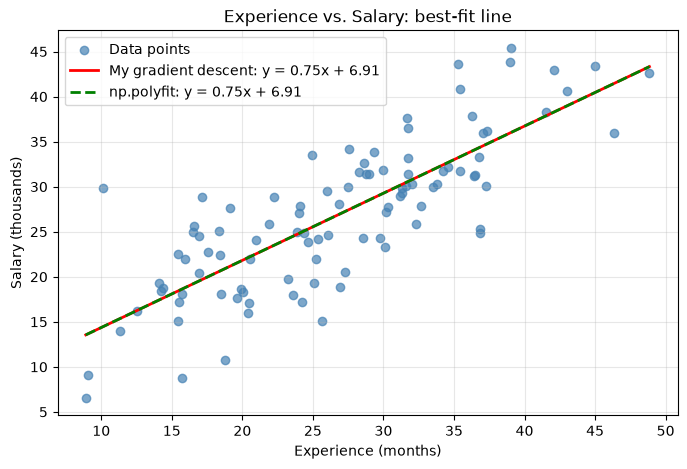

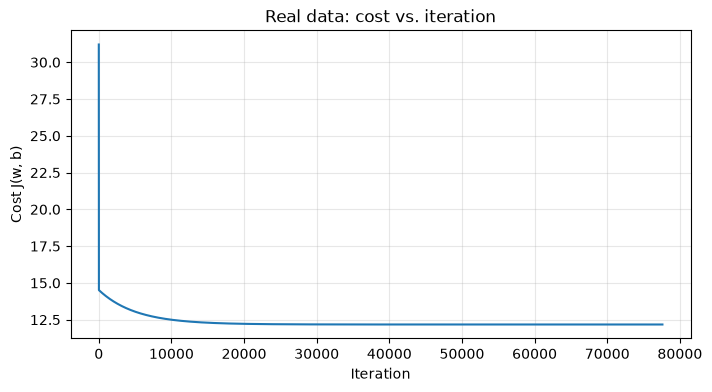

In [14]:
plot_fit(x_real, y_real, w_r, b_r,
         "Experience (months)", "Salary (thousands)",
         "Experience vs. Salary: best-fit line")
plot_cost(J_real, "Real data: cost vs. iteration")

**Result:** again my model and scikit-learn agree, so the implementation is correct. However, the final cost is much higher than in Experiment 1. The points are widely scattered around the line, which means the error comes from the **data** (noise, and other factors besides experience), not from the algorithm. Gradient descent converged perfectly; a straight line with one feature simply cannot explain this data better.

## 7. Effect of the learning rate on raw (unscaled) data

The size of each step is `alpha x gradient`. The gradient for `w` contains the factor `x`, so when the feature values are large the gradient is large too. Let's see how different values of alpha behave on this raw data.

In [15]:
w_ref, b_ref = np.polyfit(x_real, y_real, 1)
alphas = [0.1, 0.01, 0.001, 0.0001]
rows, histories = [], {}

for a in alphas:
    w_a, b_a, J_a = gradient_descent(x_real, y_real, 0, 0, alpha=a,
                                     num_iters=20000, verbose=False)
    diverged = not np.isfinite(J_a[-1])
    histories[a] = J_a
    rows.append({
        "alpha": a,
        "status": "diverged" if diverged else "stable",
        "final w": None if diverged else round(w_a, 4),
        "final b": None if diverged else round(b_a, 4),
        "final cost": None if diverged else round(J_a[-1], 4),
        "|b - b_ref|": None if diverged else round(abs(b_a - b_ref), 4),
    })

print(f"Reference (np.polyfit): w = {w_ref:.4f}, b = {b_ref:.4f}\n")
pd.DataFrame(rows)

C:\Users\Aqib kHAN\AppData\Local\Temp\ipykernel_5168\3575450291.py:7: RuntimeWarning: overflow encountered in scalar power
  total_cost += (f_wb - y[i]) ** 2
C:\Users\Aqib kHAN\AppData\Local\Temp\ipykernel_5168\3575450291.py:7: RuntimeWarning: overflow encountered in scalar add
  total_cost += (f_wb - y[i]) ** 2


Diverged at iteration 80: cost became inf. Try a smaller alpha.
Diverged at iteration 180: cost became inf. Try a smaller alpha.
Reference (np.polyfit): w = 0.7453, b = 6.9147



,alpha,status,final w,final b,final cost,|b - b_ref|
0,0.1000,diverged,NaN,NaN,NaN,NaN
1,0.0100,diverged,NaN,NaN,NaN,NaN
2,0.0010,stable,0.7775,5.9627,12.2194,0.9519
3,0.0001,stable,0.9362,1.2681,13.7530,5.6466


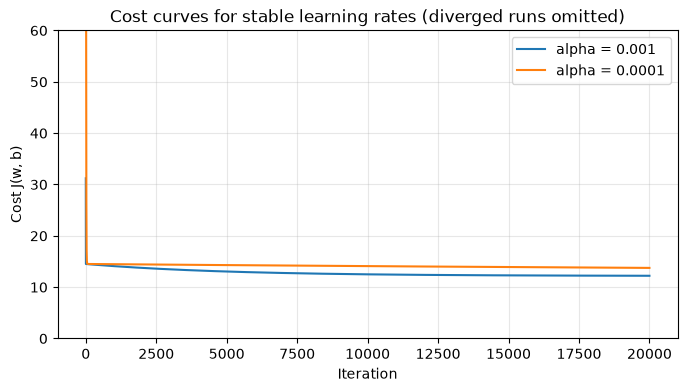

In [16]:
plt.figure(figsize=(8, 4))
for a, J_a in histories.items():
    if np.isfinite(J_a[-1]):
        plt.plot(J_a, label=f"alpha = {a}")
plt.xlabel("Iteration")
plt.ylabel("Cost J(w, b)")
plt.title("Cost curves for stable learning rates (diverged runs omitted)")
plt.ylim(0, 60)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**What this shows:**

- **alpha too large (0.1, 0.01):** each step overshoots the minimum and lands higher on the other side. The cost grows every step until the numbers overflow to `inf` / `nan`.
- **alpha = 0.001:** small enough not to overshoot, large enough to make good progress. Best of the tested values.
- **alpha = 0.0001:** stable, but each step is tiny, so convergence is slow. `b` in particular is still far from its final value after many iterations.

For this raw data there is only a narrow window of workable alphas. Anything above it diverges and anything below it crawls.

## 8. Key Learnings

**1. The learning rate depends on the scale of the features.**
When the feature values are small or moderate, a moderate alpha (for example 0.01) works. When the feature values are large, the gradients are large, so alpha must be very small to avoid overshooting, and a very small alpha makes convergence slow. This is why **feature scaling** is needed: it puts the features in a similar range so that a reasonable alpha works and training is faster. (What matters is the *size of the values*, not the number of rows.)

**2. Model performance depends on data quality.**
If the data is scattered and noisy, even the best-fit line leaves large errors and the final cost stays high. Gradient descent can converge perfectly and still give a poor-looking fit. Here, gradient descent and scikit-learn gave the same answer on the salary data, which shows that the limit came from the data and not from the algorithm.

**3. Real-world outcomes depend on multiple features.**
A target like salary is rarely explained by one input. Experience matters, but so do role, skills, education, and company. A one-feature model treats all of these as noise, which is part of why the salary data is so scattered. This motivates **multiple linear regression**: $f(\mathbf{x}) = w_1x_1 + w_2x_2 + \dots + b$.

**Other takeaways**

- Test functions on a tiny dataset with known answers before trusting them.
- Plot the cost against iterations. With a good alpha it should decrease on every iteration; if it goes up, alpha is too large or there is a bug.
- Verify your own implementation against a trusted library (scikit-learn / `np.polyfit`).

## 9. Next Steps

- Multiple features (multiple linear regression)
- Feature scaling, then re-run Section 7 and compare the workable alpha range
- Vectorization with NumPy instead of Python loops